# Manual Day — Finding Structure in Data

Closed-agent, ~60 min. Complete every `# FILL IN` cell, then run the check.

**Three problems. Work in order, as many as time permits.** The last one is a challenge.

Problems 2 and 3 use PySR and ripser. If they aren't on your laptop yet, open a terminal
now and run `pip install pysr ripser`, then `python -c "import pysr"`. The first PySR
import downloads Julia and takes a few minutes, so let it run while you do Problem 1.

## Mini-lecture: PCA and symbolic regression

### PCA

Data in many dimensions often lives near a much smaller flat subspace, and PCA finds it.
Put the $N$ samples in the rows of $X$, subtract each column's mean, and form the
covariance matrix

$$C = \frac{1}{N} X^T X,$$

a symmetric $d \times d$ matrix. The variance of the data along a unit vector $v$ is
$v^T C v$. Maximizing that over unit vectors gives $C v = \lambda v$, so the direction of
largest variance is the top eigenvector, and its eigenvalue is the variance along it.
The next eigenvector is the best direction perpendicular to the first, and so on down.
These are the principal components.

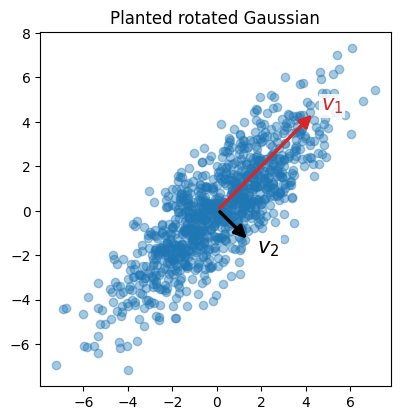

That's the data from Problem 1, a Gaussian stretched along the 45° line. The arrows are
the two eigenvectors of its covariance, each $2\sqrt{\lambda_k}$ long (two standard
deviations). $v_1$ points along the stretch and $v_2$ across it.

Component $k$ explains a fraction $\lambda_k / \sum_j \lambda_j$ of the variance. If
the first few fractions add up to nearly 1, the data is effectively that many
dimensional, and projecting onto those eigenvectors, $Z = X\,[\,v_1 \; v_2 \; \cdots]$,
keeps nearly all of it. PCA only finds flat structure. A loop needs a different tool,
and that's Problem 3, where you'll learn about persistent homology.

### Symbolic regression

A fit usually starts from a formula you chose, and least squares finds its parameters.
Symbolic regression searches for the formula too. An expression is a tree whose leaves
are variables and constants and whose internal nodes are operators like $+$, $\times$,
or $\sin$. Its complexity is the number of nodes, so $1/r^2$, written `inv(x0 * x0)`,
has complexity 4.

[PySR](https://github.com/MilesCranmer/PySR) searches by a genetic algorithm, which you learned about a few weeks ago. It keeps
populations of trees and mutates them, for example by swapping one operator for another
or grafting on a subtree. Trees with lower loss survive and breed, and their constants
get optimized numerically along the way. The output is the hall of fame, the lowest-loss expression
it found at each complexity.

A more complex formula always fits at least as well, so the lowest loss isn't the
answer. Look for the complexity where the loss falls sharply and then levels off. PySR
measures that drop with a score, $-\Delta \ln(\text{loss}) / \Delta(\text{complexity})$.
Its default pick, `model.sympy()`, takes the highest score among formulas whose loss is
within 1.5 times the lowest. On noisy data that rule can throw out the right answer,
because long formulas that fit the noise drag the lowest loss down.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(0)

In [2]:
# GIVEN: a planted 2-D Gaussian whose covariance is diag([10, 1]) rotated by 45 deg
angle = np.pi / 4
R = np.array([[np.cos(angle), -np.sin(angle)],
              [np.sin(angle),  np.cos(angle)]])
cov = R @ np.diag([10, 1]) @ R.T
data = np.random.multivariate_normal([0, 0], cov, size=1000)
data.shape

(1000, 2)

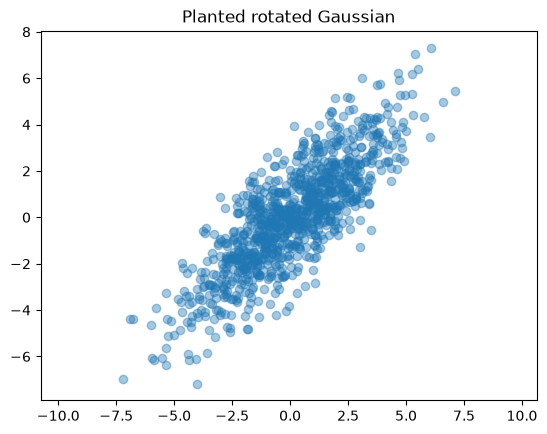

In [3]:
# GIVEN: look at the data
plt.scatter(data[:, 0], data[:, 1], alpha=0.4)
plt.axis('equal')
plt.title('Planted rotated Gaussian')
plt.show()

## Problem 1 — PCA from scratch

The covariance above is `diag([10, 1])` rotated by 45 deg, so you already know the answer:

- eigenvalues of the covariance $\approx [10, 1]$
- explained-variance ratio $\approx [10/11, 1/11] = [0.909, 0.091]$
- leading eigenvector $\approx \pm(0.707, 0.707)$, the 45 deg direction

Get these back from the samples in plain NumPy and run the check. It also prints
sklearn's answer for comparison.

In [4]:
# FILL IN: PCA from scratch  (center -> covariance -> eig -> sort -> explained-variance ratio)
N = data.shape[0]
# 1. center the data (subtract the column means)
centered = data-np.mean(data,0)
# 2. form the covariance matrix C = centered.T @ centered / N
C = centered.T @ centered / N
# 3. eigen-decompose the covariance with np.linalg.eig
print(C)
eigvals, eigvecs = np.linalg.eig(C)
# 4. sort eigenvalues (and their eigenvectors) in descending order
print(np.size(eigvecs))
order = np.argsort(eigvals)[::-1]
eigvals = eigvals[order]
eigvecs = eigvecs[:,order]
# 5. explained-variance ratio = eigenvalue / sum of eigenvalues
explained = eigvals / np.sum(eigvals)

[[5.18691103 4.26523044]
 [4.26523044 5.27115923]]
4


In [5]:
# CHECK (given): compare against the known answer
print('eigenvalues:', np.round(eigvals, 3))
print('explained-variance ratio:', np.round(explained, 3))
print('leading eigenvector:', np.round(eigvecs[:, 0], 3))

assert np.allclose(np.sort(eigvals)[::-1], [10, 1], atol=1.0), 'eigenvalues should be ~[10, 1]'
assert np.allclose(np.abs(explained), [10/11, 1/11], atol=0.05), 'EVR should be ~[0.909, 0.091]'
assert abs(abs(eigvecs[0, 0]) - 0.707) < 0.06, 'leading eigenvector should be ~(0.707, 0.707)'
print('PASS')

# cross-check vs sklearn (does not affect the check above)
try:
    from sklearn.decomposition import PCA
    print('sklearn EVR:', np.round(PCA(n_components=2).fit(data).explained_variance_ratio_, 3))
except Exception as e:
    print('sklearn cross-check skipped:', e)

eigenvalues: [9.494+0.j 0.964+0.j]
explained-variance ratio: [0.908+0.j 0.092+0.j]
leading eigenvector: [-0.704+0.j -0.711+0.j]
PASS
sklearn EVR: [0.908 0.092]


### A message from ten dimensions

Now run PCA on something you can't look at directly. `message.npy` holds 1,460 points
in ten dimensions, and there's a message in them. Center the data, diagonalize its
covariance, and project onto the top two eigenvectors to get `Z`, with shape
`(1460, 2)`. The plot is given.

Use `np.linalg.eigh` this time. It's made for symmetric matrices like the covariance,
and it returns the eigenvalues in ascending order, so the top two eigenvectors are the
last two columns, largest first. An eigenvector is only defined up to a sign, so if the
message comes out mirrored or upside down, flip the sign of a column of `Z`.

**Known answer.** Two components carry 98% and 2% of the variance and the other eight
carry none. You'll know the message when you see it.

In [6]:
# GIVEN: 1,460 points in ten dimensions
msg = np.load("message.npy")
msg.shape

(1460, 10)

(10, 10)
(1460, 10)
(1460, 2)


c:\Users\wrl62\miniconda3\Lib\site-packages\matplotlib\cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\wrl62\miniconda3\Lib\site-packages\matplotlib\collections.py:205: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)


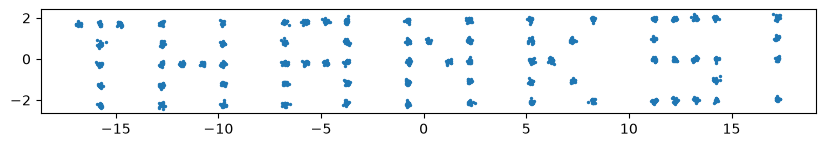

In [7]:
# FILL IN: center msg, diagonalize its covariance with np.linalg.eigh, and project onto
# the top two eigenvectors as Z, shape (1460, 2). Flip signs until the message reads right.
msg_centered = msg-np.mean(msg,0)
Cov = msg_centered.T @ msg_centered / msg.shape[0]
msg_eigval, msg_eigvec = np.linalg.eig(Cov)
order2 = np.argsort(msg_eigval)[::-1]
msg_eigval = msg_eigval[order2]
msg_eigvec = msg_eigvec[:,order2]
print(msg_eigvec.shape)
print(msg_centered.shape)
Z = msg_centered @ msg_eigvec[:, 0:2]
print(Z.shape)
# 5. explained-variance ratio = eigenvalue / sum of eigenvalues
explained = eigvals / np.sum(eigvals)

plt.figure(figsize=(10, 2))           # GIVEN: equal axes, or the message gets squashed
plt.scatter(Z[:, 0], Z[:, 1], s=2)
plt.gca().set_aspect("equal")
plt.show()

In [8]:
# CHECK (given): the first three points, projected the right way up
upright = np.array([[-16.754, 1.687039], [-16.783599, 1.75164], [-16.928352, 1.691128]])
assert Z.shape == (1460, 2), f"Z should have shape (1460, 2), got {Z.shape}"
if not np.allclose(Z[:3], upright, atol=1e-4):
    assert np.allclose(np.abs(Z[:3]), np.abs(upright), atol=1e-4), (
        "Z doesn't match: center msg, then project onto the eigenvectors with the two "
        "largest eigenvalues, largest first")
    raise AssertionError("right numbers, wrong signs: flip the column of Z that makes the "
                         "message read backward or upside down")
print(f"Z keeps {100 * Z.var(axis=0).sum() / msg.var(axis=0).sum():.1f}% of the variance")
print("PASS")

Z keeps 100.0% of the variance
PASS


## Problem 2 — Symbolic regression

The data is a planted law, $F = 1/r^2$ for $r$ from 0.1 to 1, once clean and once with
20% noise.

1. Make a `PySRRegressor` with `binary_operators=["+", "*"]` and
   `unary_operators=["cos", "exp", "sin", "inv(x) = 1/x"]`. `inv` is a custom operator
   written in Julia, so also pass `extra_sympy_mappings={"inv": lambda x: 1 / x}` to tell
   sympy what it means. The search settings are given.
2. Fit the clean data with `model.fit(r, F)`, and save its best formula, `model.sympy()`,
   as `clean_law`.
3. Fit the noisy data and print the hall of fame,
   `model.equations_[["complexity", "loss", "equation"]]`. Find the row where the loss
   stops falling fast. Save its index as `noisy_row` and its formula as
   `noisy_law = model.sympy(noisy_row)`.

**Known answers.** Each fit takes about 10 seconds. On clean data PySR finds $1/r^2$. On
noisy data the loss falls from over 300 to about 6 at complexity 4, which is $1/r^2$,
and barely moves after that. `model.sympy()` misses it and picks a formula of
complexity 10 that fits some of the noise. The check wants `clean_law` to be $1/r^2$,
and the formula at `noisy_row` to have complexity 6 or less and stay within 5% of
$1/r^2$.

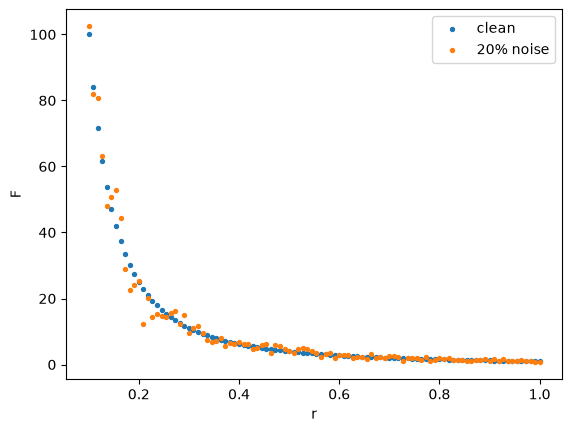

In [3]:
# GIVEN: PySR, and the planted law F = 1/r^2, clean and with 20% noise
import os
os.environ["PYTHON_JULIACALL_HANDLE_SIGNALS"] = "yes"    # PySR's docs ask for this in Jupyter
from pysr import PySRRegressor

r = np.linspace(0.1, 1, 100).reshape(-1, 1)     # a column: PySR wants (samples, features)
F = 1 / r[:, 0] ** 2
F_noisy = F + np.random.default_rng(0).normal(0, 0.2 * F)

plt.scatter(r, F, s=8, label="clean")
plt.scatter(r, F_noisy, s=8, label="20% noise")
plt.xlabel("r"); plt.ylabel("F"); plt.legend()
plt.show()

In [4]:
# FILL IN: the model, then the fit to the clean data
model = PySRRegressor(
    niterations=40, verbosity=0, progress=False,                # GIVEN
    random_state=0, deterministic=True, parallelism="serial",   # GIVEN: the same search for everyone
    # FILL IN: binary_operators, unary_operators, and extra_sympy_mappings for inv
    binary_operators=["*","+"],unary_operators=["cos","sin","exp","inv(x)=1/x"],
    extra_sympy_mappings={"inv": lambda x : 1/x}
)
# FILL IN: fit the clean data, then save model.sympy() as clean_law
model.fit(r,F)
clean_law = model.sympy()
print("clean:", clean_law)

clean: -0.84645325 + 0.84645325 - 1.0527183/x0 - 0.94728184/x0 + 1/(x0*x0) + 1/x0 + 1/x0


In [6]:
# FILL IN: fit the noisy data and print the hall of fame (complexity, loss, equation)
# FILL IN: the row where the loss stops falling fast as noisy_row, and its formula as noisy_law
A = model.equations_[["complexity","loss","equation"]]
print(A)
#print("noisy:", noisy_law)

    complexity          loss  \
0            1  3.107441e+02   
1            2  3.103798e+02   
2            3  3.098550e+02   
3            4  1.117968e-12   
4            5  9.798384e-13   
5            7  9.794121e-13   
6            9  3.609557e-13   
7           14  3.605294e-13   
8           17  3.043965e-13   
9           19  2.920331e-13   
10          20  2.717471e-13   
11          25  1.222134e-13   

                                             equation  
0                                           10.420727  
1                                             inv(x0)  
2                                        inv(sin(x0))  
3                                        inv(x0 * x0)  
4                                   inv(x0) * inv(x0)  
5                           (inv(x0) * inv(x0)) + 0.0  
6             inv(x0) * inv(x0 + (x0 * 3.6267913e-8))  
7   inv(((x0 * cos(x0 * -0.38986555)) * 3.6267913e...  
8   (((inv(x0) * inv(x0)) + (inv(x0) * -1.0000001)...  
9   (inv(x0) + -1.33706

In [ ]:
# CHECK (given): both laws against 1/r^2
import sympy
r_check = np.linspace(0.1, 1, 200)
truth = 1 / r_check ** 2

syms = list(clean_law.free_symbols)
assert len(syms) == 1, "clean_law should be a formula in x0, which is r"
clean_err = np.max(np.abs(sympy.lambdify(syms[0], clean_law, "numpy")(r_check) / truth - 1))
complexity = int(model.equations_.loc[noisy_row, "complexity"])
noisy_err = np.max(np.abs(model.predict(r_check.reshape(-1, 1), index=noisy_row) / truth - 1))
print(f"clean law: {clean_law}, off from 1/r^2 by at most {100 * clean_err:.2g}%")
print(f"noisy pick: {noisy_law}, complexity {complexity}, off by at most {100 * noisy_err:.2g}%")

assert clean_err < 1e-3, "clean_law should be 1/r^2. Did you fit the clean data?"
assert complexity <= 6, (f"complexity {complexity} is fitting the noise. Look for the row where "
                         "the loss stops falling fast")
assert noisy_err < 0.05, ("that formula is more than 5% off 1/r^2. Look for the row where the "
                          "loss falls the most")
print("PASS")

## Problem 3 — Challenge: persistent homology

Grow a ball around every point in a data set. When the balls are tiny you see only
points, and when they're huge you see one blob. In between, the union of the balls can
take the shape the data was sampled from, a loop for instance. Persistent homology
follows each feature across every radius and records when it's born and when it dies.

The bookkeeping uses the Vietoris-Rips complex. At scale $\epsilon$, join two points
with an edge if they're within $\epsilon$ of each other, and fill in a triangle once all
three of its edges are there. $H_0$ counts connected components: each point starts as
its own component at $\epsilon = 0$, and one component dies every time an edge joins two
of them. $H_1$ counts loops: a loop is born when the edge that closes it appears, and
dies when triangles fill it in. Every feature becomes a point (birth, death) on a
persistence diagram. Points far above the diagonal lived a long time and are structure
in the data. Points close to it are noise.

`ripser(X)["dgms"]` returns `[H0, H1]`, each an array with one (birth, death) row per
feature. One component never dies, and its death is `inf`.

**(a) By hand.** Take four points at the corners of a unit square. On paper, find when
the components die, and when the one loop is born and dies. Save the three finite $H_0$
deaths as `square_h0` and the loop as `square_h1 = (birth, death)`.

**(b) A circle.** The data below are 100 noisy points on a circle of radius $R = 2$. Run
ripser on them and save the (birth, death) row of the longest-lived $H_1$ feature as
`loop`. Then predict when it dies, as `predicted_death` in terms of `R`. Triangles can
only fill the loop once one of them covers the center, which takes three points spread
around the circle. The smallest triangle that does it is equilateral.

**Known answers.** The check runs ripser on the square and wants (a) to agree with it.
In (b), ripser's death for the loop should match your prediction to within 5%. The
noise pulls it about 1% low.

In [ ]:
# GIVEN: ripser, and 100 noisy points on a circle of radius R
from ripser import ripser

R = 2.0
rng = np.random.default_rng(0)
theta = rng.uniform(0, 2 * np.pi, 100)
circle = R * np.column_stack([np.cos(theta), np.sin(theta)]) + rng.normal(0, 0.02, (100, 2))

plt.scatter(circle[:, 0], circle[:, 1], s=8)
plt.gca().set_aspect("equal")
plt.show()

In [ ]:
# FILL IN (a): the square by hand. The three finite H0 deaths, and the loop's (birth, death).

In [ ]:
# FILL IN (b): ripser on the circle, the longest-lived H1 row as loop, and your prediction
# for its death as predicted_death, in terms of R

In [ ]:
# CHECK (given): (a) against ripser, (b) against your prediction, then the circle's diagram
square = np.array([[0, 0], [1, 0], [1, 1], [0, 1]], dtype=float)
sq_h0, sq_h1 = ripser(square)["dgms"]
assert np.allclose(np.sort(square_h0), np.sort(sq_h0[np.isfinite(sq_h0[:, 1]), 1])), (
    "(a) those aren't ripser's H0 deaths. At what distance do the sides of the square appear?")
assert len(sq_h1) == 1 and np.allclose(square_h1, sq_h1[0], atol=1e-6), (
    "(a) the loop is born when the square closes, and dies once triangles can fill it")
print("(a) agrees with ripser")

c_h0, c_h1 = ripser(circle)["dgms"]
longest = c_h1[np.argmax(c_h1[:, 1] - c_h1[:, 0])]
assert np.allclose(loop, longest), "(b) loop should be the H1 row with the largest death minus birth"
print(f"(b) the loop lives from {loop[0]:.3f} to {loop[1]:.3f}, and you predicted {predicted_death:.3f}")
assert abs(loop[1] / predicted_death - 1) < 0.05, (
    "(b) your prediction is more than 5% off. How long is the side of an equilateral "
    "triangle inscribed in a circle of radius R?")
print("PASS")

finite = np.isfinite(c_h0[:, 1])
top = 1.1 * longest[1]
plt.figure(figsize=(4, 4))
plt.scatter(c_h0[finite, 0], c_h0[finite, 1], s=10, label="$H_0$")
plt.scatter(c_h1[:, 0], c_h1[:, 1], s=25, label="$H_1$")
plt.plot([0, top], [0, top], "k--", lw=1)
plt.xlabel("birth")
plt.ylabel("death")
plt.legend()
plt.title("the circle's persistence diagram")
plt.show()